# Đồ thị 10 Số hồ sơ có từng đặc điểm bệnh sử và hút thuốc

**Võ Minh Huy — 2311110117**

Tổng hợp riêng bốn biến anaemia, diabetes, high_blood_pressure và smoking. Với mỗi biến, đếm số mã 1 và tính tỷ lệ trên đủ 299 hồ sơ. Mã 1 thể hiện có đặc điểm tương ứng; smoking là tình trạng hút thuốc, không phải một bệnh.

Một hồ sơ có thể có nhiều đặc điểm. Bốn cột không phải các nhóm loại trừ nhau; không cộng chúng để suy ra số bệnh nhân khác nhau hoặc yêu cầu tổng phần trăm bằng 100%. Không cần DEATH_EVENT nên vẫn dùng hồ sơ chờ xác minh nhãn.


In [1]:
from pathlib import Path
import sys
import subprocess
import numpy as np
import pandas as pd
try:
    import matplotlib.pyplot as plt
except ModuleNotFoundError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "matplotlib"])
    import matplotlib.pyplot as plt

thu_muc = Path.cwd()
if thu_muc.name == "python":
    thu_muc = thu_muc.parent
du_lieu = pd.read_csv(thu_muc / "VoMinhHuy_Heart Failure Prediction_after_Python.csv")
cot = ["anaemia","diabetes","high_blood_pressure","smoking"]
mo_ta = ["Thiếu máu","Đái tháo đường","Tăng huyết áp","Hút thuốc"]
gia_tri = du_lieu[cot].apply(pd.to_numeric,errors="raise")
if len(gia_tri) != 299 or not gia_tri.isin([0,1]).all().all():
    raise ValueError("Cần đủ 299 hồ sơ, bốn biến chỉ chứa 0 hoặc 1 và không thiếu.")
thu_muc_kq = thu_muc / "ket_qua/21_do_thi/10_bar_dac_diem"
thu_muc_kq.mkdir(parents=True,exist_ok=True)
bang_tong_hop = pd.DataFrame({"ThuocTinh":cot,"MoTa":mo_ta,
    "SoCoMa1":[int(gia_tri[c].eq(1).sum()) for c in cot],
    "SoKhongMa0":[int(gia_tri[c].eq(0).sum()) for c in cot],
    "MauSo":[len(gia_tri)]*4})
bang_tong_hop["TyLeCoPhanTram"] = 100*bang_tong_hop["SoCoMa1"]/bang_tong_hop["MauSo"]
assert bang_tong_hop["SoCoMa1"].tolist() == [129,125,105,96]
assert (bang_tong_hop["SoCoMa1"]+bang_tong_hop["SoKhongMa0"]).eq(299).all()
bang_tong_hop.round(2)


,ThuocTinh,MoTa,SoCoMa1,SoKhongMa0,MauSo,TyLeCoPhanTram
0,anaemia,Thiếu máu,129,170,299,43.14
1,diabetes,Đái tháo đường,125,174,299,41.81
2,high_blood_pressure,Tăng huyết áp,105,194,299,35.12
3,smoking,Hút thuốc,96,203,299,32.11


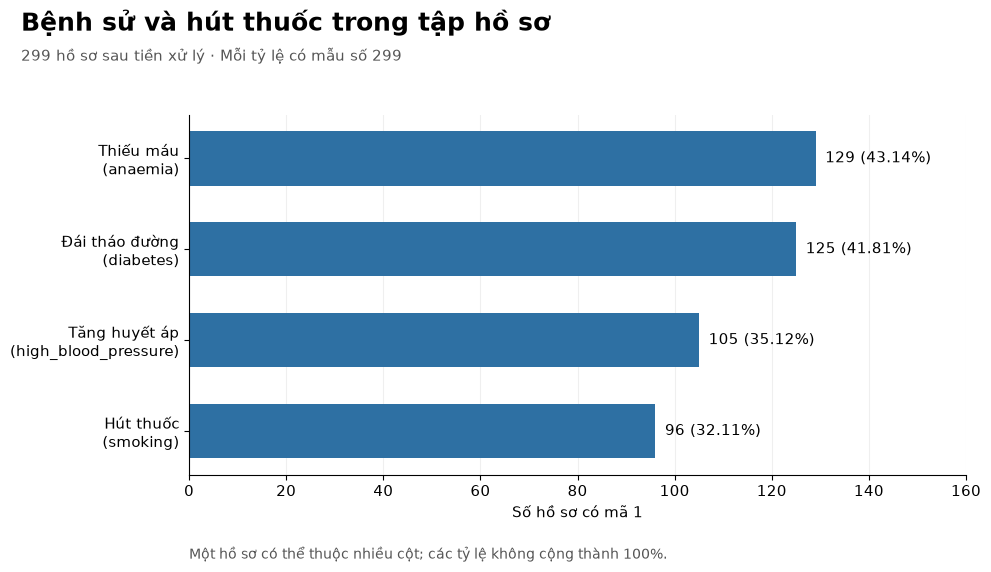

In [2]:
plt.rcParams.update({"font.family":"DejaVu Sans","font.size":11})
fig, ax = plt.subplots(figsize=(10.5,6))
fig.subplots_adjust(top=0.80,bottom=0.20,left=0.24,right=0.98)
fig.text(0.08,0.94,"Bệnh sử và hút thuốc trong tập hồ sơ",fontsize=18,weight="bold")
fig.text(0.08,0.89,"299 hồ sơ sau tiền xử lý · Mỗi tỷ lệ có mẫu số 299",color="#555555")
y = np.arange(4)
cot_ve = ax.barh(y,bang_tong_hop["SoCoMa1"],height=0.60,color="#2E70A3")
assert [int(c.get_width()) for c in cot_ve] == [129,125,105,96]
for c, r in zip(cot_ve,bang_tong_hop.to_dict("records")):
    ax.text(c.get_width()+2,c.get_y()+c.get_height()/2,
        f'{r["SoCoMa1"]} ({r["TyLeCoPhanTram"]:.2f}%)',va="center",fontsize=11)
ax.set_yticks(y,labels=["Thiếu máu\n(anaemia)","Đái tháo đường\n(diabetes)",
    "Tăng huyết áp\n(high_blood_pressure)","Hút thuốc\n(smoking)"])
ax.invert_yaxis()
ax.set(xlabel="Số hồ sơ có mã 1",xlim=(0,160))
ax.set_xticks(np.arange(0,161,20))
ax.grid(axis="x",alpha=0.2)
ax.set_axisbelow(True)
ax.spines[["top","right"]].set_visible(False)
fig.text(0.24,0.06,"Một hồ sơ có thể thuộc nhiều cột; các tỷ lệ không cộng thành 100%.",fontsize=10,color="#555555")
fig.savefig(thu_muc_kq / "10_bar_dac_diem.png",dpi=300,bbox_inches="tight",facecolor="white")
bang_tong_hop.to_csv(thu_muc_kq / "tong_hop_python.csv",index=False,encoding="utf-8-sig")
plt.show()


## Nhận xét

Thiếu máu có 129 hồ sơ (43,14%), đái tháo đường 125 (41,81%), tăng huyết áp 105 (35,12%) và hút thuốc 96 (32,11%). Trong bốn đặc điểm được khảo sát, mã 1 của anaemia có số hồ sơ cao nhất; smoking thấp nhất.

Đây là bốn phép đếm riêng trên cùng 299 hồ sơ. Một hồ sơ có thể xuất hiện trong nhiều phép đếm, nên tổng số mã 1 không phải số bệnh nhân khác nhau. Các tỷ lệ chỉ mô tả tập dữ liệu, không phải tỷ lệ hiện mắc trong dân số hoặc mức ảnh hưởng của từng yếu tố đến tử vong. Giữ nguyên file after.
